## 분석: 전체 데이터 파일 수 확인

In [5]:
from pathlib import Path

# 상위 폴더에 있는 data 폴더 접근
data_path = Path("../data")

# 하위 폴더까지 포함한 전체 파일 수
files = [f for f in data_path.rglob("*") if f.is_file()]

print(f"전체 파일 수: {len(files):,}개")

전체 파일 수: 1,838개


## 분석: 이미지 종류별 파악

In [ ]:
from collections import Counter # 데이터에서 각 항목이 몇 번 등장하는지 세는 도구

# 확장자별 개수 계산
extension_counts = Counter(
    f.suffix.lower() for f in files
)

for ext, count in extension_counts.items():
    print(f"{ext or '(확장자 없음)'}: {count:,}개")

.md: 1개
.png: 1,074개
.json: 763개


## 분석: 랜덤 이미지 시각화
- 이미지 확장자를 가진 파일만 추려 최대 9개를 중복 없이 랜덤으로 선택했다.
- 선택한 이미지를 3×3 격자로 시각화하고, 각 이미지의 파일명을 표시했다.
- 이미지의 외형과 배경 등 데이터의 전반적인 구성을 살펴보았다.


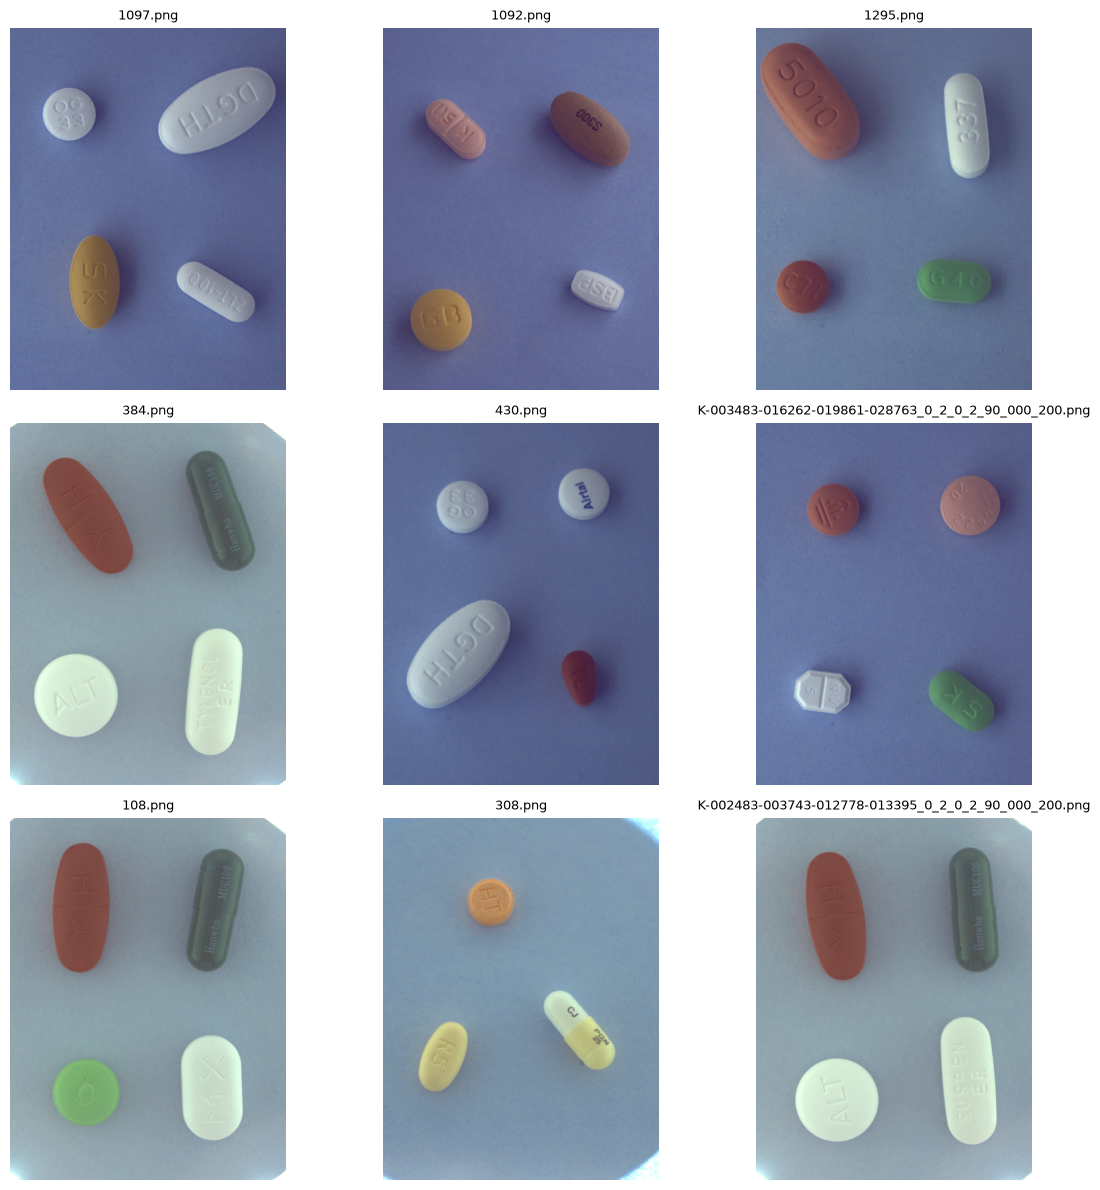

In [15]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# 이미지 파일만 추리기
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
image_files = [f for f in files if f.suffix.lower() in image_extensions]

# 중복 없이 최대 9개 랜덤 선택
sample_files = random.sample(image_files, min(9, len(image_files)))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, path in zip(axes.flat, sample_files):
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(path.name, fontsize=9)

plt.tight_layout()
plt.show()

## 분석: 이미지 크기 확인

- 전체 이미지 파일의 가로와 세로 크기를 확인했다.
- `(가로, 세로)` 조합별 이미지 개수를 집계하여 크기 분포를 확인했다.
- 이미지 크기 종류가 1개인지 확인하여 크기의 통일 여부를 판단했다.
- 읽기 오류가 발생한 파일은 별도로 기록했다.

In [16]:
from collections import Counter
from PIL import Image

size_counts = Counter()
failed_files = []

for path in image_files:
    try:
        with Image.open(path) as img:
            size_counts[img.size] += 1  # (가로, 세로)
    except Exception as e:
        failed_files.append((path.name, str(e)))

print(f"확인한 이미지: {sum(size_counts.values()):,}개")
print(f"이미지 크기 종류: {len(size_counts):,}개\n")

for (width, height), count in size_counts.most_common():
    print(f"{width} × {height}: {count:,}개")

if not size_counts:
    print("\n확인 가능한 이미지가 없어.")
elif len(size_counts) == 1:
    print("\n확인한 이미지의 크기가 모두 동일해.")
else:
    print("\n이미지 크기가 서로 달라.")

if failed_files:
    print(f"\n⚠️ 읽지 못한 이미지: {len(failed_files):,}개")

확인한 이미지: 1,074개
이미지 크기 종류: 1개

976 × 1280: 1,074개

확인한 이미지의 크기가 모두 동일해.


## 분석: 전체 이미지의 색상 모드를 확인한다.

- 1,074개의 이미지가 모두 RGB 모드로 구성되어 있음을 확인하였다.

In [25]:
from PIL import Image
from collections import Counter

image_modes = []

for file in image_files:
    with Image.open(file) as img:
        image_modes.append(img.mode)

mode_counts = Counter(image_modes)

print("이미지 채널별 개수")

for mode, count in mode_counts.items():
    print(f"{mode}: {count:,}개")

이미지 채널별 개수
RGB: 1,074개
